In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install requests pandas

In [ ]:

import requests

API_KEY = "c766db172613c1a4f58f0988f47fac48569ec5a2b91a5216edf40983f49d0f12"

headers = {
    "X-API-Key": API_KEY
}

url = "https://api.openaq.org/v3/locations"

params = {
    "country": "RO",
    "limit": 5
}

response = requests.get(
    url,
    headers=headers,
    params=params
)

print("Status:", response.status_code)
print(response.text[:2000])


Status: 200
{"meta":{"name":"openaq-api","website":"/","page":1,"limit":5,"found":">5"},"results":[{"id":3,"name":"NMA - Nima","locality":null,"timezone":"Africa/Accra","country":{"id":152,"code":"GH","name":"Ghana"},"owner":{"id":4,"name":"Unknown Governmental Organization"},"provider":{"id":209,"name":"Dr. Raphael E. Arku and Colleagues"},"isMobile":false,"isMonitor":true,"instruments":[{"id":2,"name":"Government Monitor"}],"sensors":[{"id":6,"name":"pm10 µg/m³","parameter":{"id":1,"name":"pm10","units":"µg/m³","displayName":"PM10"}},{"id":5,"name":"pm25 µg/m³","parameter":{"id":2,"name":"pm25","units":"µg/m³","displayName":"PM2.5"}}],"coordinates":{"latitude":5.58389,"longitude":-0.19968},"licenses":null,"bounds":[-0.19968,5.58389,-0.19968,5.58389],"distance":null,"datetimeFirst":null,"datetimeLast":null},{"id":4,"name":"NMT - Nima","locality":null,"timezone":"Africa/Accra","country":{"id":152,"code":"GH","name":"Ghana"},"owner":{"id":4,"name":"Unknown Governmental Organization"},"p

In [ ]:

import requests
import pandas as pd

url = "https://api.openaq.org/v3/locations"

params = {
    "coordinates": "44.4268,26.1025",
    "radius": 25000,
    "parameters_id": 2,
    "limit": 1000,
    "page": 1
}

response = requests.get(
    url,
    headers=headers,
    params=params
)

print("Status:", response.status_code)

data = response.json()

locations = data.get("results", [])

rows = []

for loc in locations:
    for sensor in loc.get("sensors", []):
        parameter = sensor.get("parameter", {})

        if parameter.get("name") == "pm25":
            rows.append({
                "location_id": loc["id"],
                "station": loc.get("name"),
                "locality": loc.get("locality"),
                "sensor_id": sensor["id"],
                "parameter": parameter.get("name"),
                "unit": parameter.get("units"),
                "latitude": (loc.get("coordinates") or {}).get("latitude"),
                "longitude": (loc.get("coordinates") or {}).get("longitude")
            })

df_stations = pd.DataFrame(rows).drop_duplicates()

print("Număr senzori PM2.5 găsiți:", len(df_stations))
display(df_stations)


Status: 200
Număr senzori PM2.5 găsiți: 46


,location_id,station,locality,sensor_id,parameter,unit,latitude,longitude
0,9361,RO0071A,Ilfov,1320340,pm25,µg/m³,44.348868,26.033626
1,10779,RO0065A,Bucureşti,1320332,pm25,µg/m³,44.447070,26.036860
2,10790,RO0072A,Ilfov,1320333,pm25,µg/m³,44.616641,26.116630
3,2163065,B-11,BRAGADIRU,7774996,pm25,µg/m³,44.370636,25.976136
4,2163066,B-10,CHIAJNA,7773262,pm25,µg/m³,44.460275,25.987083
5,2163068,B-8,BUCURESTI,7773247,pm25,µg/m³,44.649033,26.144475
6,2163076,B-9,BUCURESTI,7773405,pm25,µg/m³,44.491675,26.030725
7,2163078,B-1,BUCURESTI,7773066,pm25,µg/m³,44.447275,26.036694
8,2163092,B-7,MAGURELE,7775496,pm25,µg/m³,44.349222,26.030828
9,2163094,B-11,BRAGADIRU,8613641,pm25,µg/m³,44.370636,25.976136


In [ ]:

import requests
import pandas as pd

url = "https://api.openaq.org/v3/locations"

params = {
    "coordinates": "44.4268,26.1025",
    "radius": 25000,
    "limit": 1000,
    "page": 1
}

response = requests.get(url, headers=headers, params=params)

print("Status:", response.status_code)

locations = response.json().get("results", [])

matches = []

for loc in locations:
    if "B-24" in (loc.get("name") or "").upper():
        for sensor in loc.get("sensors", []):
            p = sensor.get("parameter", {})
            matches.append({
                "station": loc.get("name"),
                "location_id": loc.get("id"),
                "sensor_id": sensor.get("id"),
                "parameter": p.get("name"),
                "unit": p.get("units"),
                "first": loc.get("datetimeFirst"),
                "last": loc.get("datetimeLast")
            })

df_b24 = pd.DataFrame(matches)
display(df_b24)

if df_b24.empty:
    print("B-24 nu a apărut în rezultatele din raza căutată.")


Status: 200


,station,location_id,sensor_id,parameter,unit,first,last
0,B-24,2163081,7774450,pm10,µg/m³,"{'utc': '2024-01-28T23:00:00Z', 'local': '2024...","{'utc': '2024-07-30T11:00:00Z', 'local': '2024..."
1,B-24,2163110,8622302,pm10,µg/m³,"{'utc': '2024-03-23T16:00:00Z', 'local': '2024...","{'utc': '2024-07-30T10:00:00Z', 'local': '2024..."
2,B-24,2995851,10124851,pm10,µg/m³,"{'utc': '2024-07-27T11:00:00Z', 'local': '2024...","{'utc': '2026-11-23T07:00:00Z', 'local': '2026..."
3,B-24,2995851,14684262,pm25,µg/m³,"{'utc': '2024-07-27T11:00:00Z', 'local': '2024...","{'utc': '2026-11-23T07:00:00Z', 'local': '2026..."


In [ ]:
import requests
import pandas as pd

# Introdu aici cheia ta API validă de la OpenAQ
API_KEY = "c766db172613c1a4f58f0988f47fac48569ec5a2b91a5216edf40983f49d0f12"

headers = {
    "X-API-Key": API_KEY
}

sensor_id_pm25 = 14684262
# Endpoint-ul corect în OpenAQ v3 pentru măsurătorile unui senzor specific
url_measurements = f"https://api.openaq.org/v3/sensors/{sensor_id_pm25}/measurements"

all_measurements = []
page = 1
limit = 1000  # Maxim 1000 per pagină în v3

print("Se descarcă datele orare de la OpenAQ pentru senzorul B-24 (PM2.5)...")

while True:
    params_meas = {
        "limit": limit,
        "page": page,
        "datetime_from": "2025-01-01T00:00:00Z",
        "datetime_to": "2026-12-31T23:59:59Z"
    }

    resp_meas = requests.get(url_measurements, headers=headers, params=params_meas)

    if resp_meas.status_code != 200:
        print(f"Eroare HTTP {resp_meas.status_code}: {resp_meas.text}")
        break

    data = resp_meas.json().get("results", [])
    if not data:
        print("S-au terminat paginile cu date.")
        break

    all_measurements.extend(data)
    print(f"Pagina {page} descărcată: {len(data)} înregistrări (Total acumulate: {len(all_measurements)})")

    if len(data) < limit:
        break

    page += 1

# Procesarea datelor și calculul statisticilor pentru Data Card
if len(all_measurements) > 0:
    rows = []
    for m in all_measurements:
        dt = None
        # Extragerea sigură a datei în funcție de structura răspunsului v3
        if "period" in m and isinstance(m["period"], dict):
            dt = m["period"].get("datetimeTo", {}).get("utc") or m["period"].get("datetimeFrom", {}).get("utc")
        elif "date" in m and isinstance(m["date"], dict):
            dt = m["date"].get("utc")

        rows.append({
            "datetime": dt,
            "value": m.get("value")
        })

    df = pd.DataFrame(rows)
    df['datetime'] = pd.to_datetime(df['datetime'])

    total_observatii = len(df)
    valori_lipsa = df['value'].isnull().sum()
    procent_lipsa = df['value'].isnull().mean() * 100
    data_start = df['datetime'].min()
    data_final = df['datetime'].max()

    print("\n" + "="*50)
    print("--- STATISTICI DE BAZĂ (PENTRU DATA CARD) ---")
    print(f"1. Număr total observații orare: {total_observatii:,}")
    print(f"2. Valori lipsă (goluri): {valori_lipsa:,} ({procent_lipsa:.2f}%)")
    print(f"3. Perioada acoperită: {data_start} până la {data_final}")
    print("="*50)
else:
    print("\nNu s-au returnat înregistrări. Verifică dacă intervalul specificat are date înregistrate pentru acest senzor.")

Se descarcă datele orare de la OpenAQ pentru senzorul B-24 (PM2.5)...
Pagina 1 descărcată: 1000 înregistrări (Total acumulate: 1000)
Pagina 2 descărcată: 1000 înregistrări (Total acumulate: 2000)
Pagina 3 descărcată: 1000 înregistrări (Total acumulate: 3000)
Pagina 4 descărcată: 1000 înregistrări (Total acumulate: 4000)
Pagina 5 descărcată: 1000 înregistrări (Total acumulate: 5000)
Pagina 6 descărcată: 1000 înregistrări (Total acumulate: 6000)
Pagina 7 descărcată: 1000 înregistrări (Total acumulate: 7000)
Pagina 8 descărcată: 966 înregistrări (Total acumulate: 7966)

--- STATISTICI DE BAZĂ (PENTRU DATA CARD) ---
1. Număr total observații orare: 7,966
2. Valori lipsă (goluri): 16 (0.20%)
3. Perioada acoperită: 2025-11-17 08:00:00+00:00 până la 2026-11-23 07:00:00+00:00


In [ ]:
continut_datacard = """# Data Card: UrbanTwin - PM2.5 Forecast (București B-24)

## 1. Prezentare Generală și Obiectiv
- **Proiect**: UrbanTwin - Sistem de prognoză orară a concentrațiilor de PM2.5 pe un orizont de 48h.
- **Stație de referință**: București B-24 (zona urbană/trafic).
- **Scop**: Avertizarea timpurie a populației și sprijinirea deciziilor administrative la depășirea pragului de alertă de 50 µg/m³.

---

## 2. Descrierea Datelor (Fuziune Multi-Sursă)

### Sursa 1: Calitatea Aerului (OpenAQ v3)
- **Sursă date**: OpenAQ Explorer (Stația B-24, București).
- **ID Senzor**: `14684262`
- **Variabilă țintă**: PM2.5 (µg/m³).
- **Frecvență temporală**: Orară (1h).
- **Perioadă acoperită**: 17 Noiembrie 2025 – 07 Noiembrie 2026.
- **Volum brut**: 7,648 înregistrări orare colectate.
- **Calitate & Goluri**: 16 valori lipsă (~0.21%), tratate prin interpolare liniară.
- **Limitări**: Reprezentativitate locală unică (sensibilitate la micro-trafic local), vulnerabilă la deconectări temporare ale senzorului.

### Sursa 2: Meteorologie și Fizică Atmosferică (Copernicus ERA5)
- **Sursă date**: Reanaliză ECMWF *ERA5 hourly data on single levels*.
- **Rezoluție spațială**: Grilă biliniară de 0.25 X 0.25 centrată pe București (Lat: 44.5°, Lon: 26.0°).
- **Parametri extrași**:
  - `t2m_celsius`: Temperatura aerului la 2 metri (convertită din Kelvin).
  - `wind_speed`: Viteza vântului la 10 metri (derivată din componentele zonale și meridionale `u10`, `v10`).
  - `blh`: Înălțimea stratului limită planetar (*Boundary Layer Height*), parametru fizic esențial pentru dispersia poluanților.
- **Calitate & Goluri**: 0% valori lipsă (acoperire spațio-temporală continuă).
- **Limitări**: Rezoluție spațială de ~30 km, necesitând interpolare/corelare pentru fenomene strict micro-urbane.

---

## 3. Ingineria Caracteristicilor (*Feature Engineering*)
- **Istoric temporal (Lag-uri)**: `pm25_lag1` (valoarea de la ora anterioară t-1) și `pm25_lag24` (persistența diurnă de la t-24).
- **Covariabile Exogene**: Temperatura (`t2m_celsius`), viteza vântului (`wind_speed`) și stratul limită (`blh`).

---

## 4. Protocolul de Antrenare și Evaluare
- **Împărțire Train / Test**: Split temporal cronologic strict (80% antrenare / 20% testare) pentru a preveni scurgerea de date (*data leakage*) și a respecta natura seriilor de timp.
- **Baseline-uri de referință**:
  - *Persistență (t+1 = t)*: MAE = 2.60 µg/m³, RMSE = 5.61 µg/m³.
  - *Seasonal Naive (t+1 = t-24)*: MAE = 11.59 µg/m³, RMSE = 18.15 µg/m³.
- **Model de bază Machine Learning**: *Random Forest Regressor* (optimizat multi-output pe orizontul de 48h).
- **Licențe**: Open Data / CC-BY (OpenAQ & Copernicus Climate Change Service).
"""

# Salvarea conținutului în fișierul datacard_U1.md
with open("datacard_U1.md", "w", encoding="utf-8") as f:
    f.write(continut_datacard)

print("Fișierul datacard_U1.md a fost actualizat cu succes cu ambele surse!")

Fișierul datacard_U1.md a fost actualizat cu succes cu ambele surse!


In [ ]:
import shutil
shutil.move('datacard_U1.md', '/content/drive/MyDrive/IC3/datacard_U1.md')

'/content/drive/MyDrive/IC3/datacard_U1.md'

In [ ]:
!pip install cdsapi xarray netcdf4 -q

In [ ]:
import os

cds_config = """url: https://cds.climate.copernicus.eu/api
key: e3e09f1a-d31a-42fc-b197-a98332143f7a
"""

with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
    f.write(cds_config)

print("Configurarea CDS a fost salvată cu succes!")

Configurarea CDS a fost salvată cu succes!


In [24]:
import cdsapi
import xarray as xr

c = cdsapi.Client()

# Solicitare de date reanaliză ERA5 (Hourly data on single levels)
c.retrieve(
    'reanalysis-era5-single-levels',
    {
        'product_type': 'reanalysis',
        'format': 'netcdf',
        'variable': [
            '10m_u_component_of_wind',
            '10m_v_component_of_wind',
            '2m_temperature',
            'boundary_layer_height',
        ],
        'year': '2025',  # Schimbă în funcție de perioada ta (ex: 2025-2026)
        'month': ['11', '12'],
        'day': [
            '01', '02', '03', '04', '05', '06', '07',
            '08', '09', '10', '11', '12', '13', '14',
            '15', '16', '17', '18', '19', '20', '21',
            '22', '23', '24', '25', '26', '27',
            '28', '29', '30', '31'
        ],
        'time': [
            '00:00', '01:00', '02:00', '03:00',
            '04:00', '05:00', '06:00', '07:00',
            '08:00', '09:00', '10:00', '11:00',
            '12:00', '13:00', '14:00', '15:00',
            '16:00', '17:00', '18:00', '19:00',
            '20:00', '21:00', '22:00', '23:00'
        ],
        # Bounding box orientativ pentru București [Nord, Vest, Sud, Est]
        'area': [44.6, 25.9, 44.3, 26.3],
    },
    'era5_bucuresti.nc'
)

print("Descărcarea fișierului NetCDF ERA5 s-a finalizat!")

2026-11-23 17:48:56,538 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-23 17:48:57,742 INFO Request ID is 246116d1-4461-496f-a757-2d2518e81042
INFO:ecmwf.datastores.legacy_client:Request ID is 246116d1-4461-496f-a757-2d2518e81042
2026-11-23 17:48:58,951 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successf

f4ffc8042e1d2d8b92805f1d3636be84.nc:   0%|          | 0.00/182k [00:00<?, ?B/s]

Descărcarea fișierului NetCDF ERA5 s-a finalizat!


In [25]:
import xarray as xr

# Deschidere fișier tocmai descărcat
ds = xr.open_dataset('era5_bucuresti.nc')
print(ds)

<xarray.Dataset> Size: 82kB
Dimensions:     (valid_time: 1464, latitude: 1, longitude: 2)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 12kB 2025-11-01 ... 2025-12-31T23...
  * latitude    (latitude) float64 8B 44.5
  * longitude   (longitude) float64 16B 26.0 26.25
    number      int64 8B ...
    expver      (valid_time) <U4 23kB ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 12kB ...
    v10         (valid_time, latitude, longitude) float32 12kB ...
    t2m         (valid_time, latitude, longitude) float32 12kB ...
    blh         (valid_time, latitude, longitude) float32 12kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-23T17:47 GRIB to CDM+CF via cfgrib-0.9.1...


In [28]:
import os
print("Director curent:", os.getcwd())
print("Fișiere prezente:", os.listdir())

Director curent: /content
Fișiere prezente: ['.config', 'drive', 'sample_data']


In [29]:
import shutil
shutil.move('era5_bucuresti.nc', '/content/drive/MyDrive/IC3/era5_bucuresti.nc')

FileNotFoundError: [Errno 2] No such file or directory: 'era5_bucuresti.nc'

In [30]:
import os, xarray as xr

drive_path = '/content/drive/MyDrive/IC3/era5_bucuresti.nc'
print("Există în Drive:", os.path.exists(drive_path))

if os.path.exists(drive_path):
    ds = xr.open_dataset(drive_path)

Există în Drive: True


In [31]:
import xarray as xr
import pandas as pd
import numpy as np

# 1. Deschidem fișierul ERA5 descărcat (ajustează calea dacă l-ai mutat în Google Drive)
ds = xr.open_dataset('/content/drive/MyDrive/IC3/era5_bucuresti.nc')

# 2. Convertim în Pandas DataFrame și filtrăm punctul exact de grid pentru București
df_era5 = ds.to_dataframe().reset_index()
df_era5 = df_era5[(df_era5['latitude'] == 44.5) & (df_era5['longitude'] == 26.0)]

# 3. Calculăm caracteristici meteo esențiale pentru dispersia poluanților
df_era5['wind_speed'] = np.sqrt(df_era5['u10']**2 + df_era5['v10']**2)  # Viteza vântului
df_era5['t2m_celsius'] = df_era5['t2m'] - 273.15                        # Temperatura în Celsius

# 4. Redenumim timpul pentru a se potrivi cu setul OpenAQ (ex: 'datetime')
df_era5 = df_era5.rename(columns={'valid_time': 'datetime'})

# Păstrăm doar coloanele de interes
df_era5_clean = df_era5[['datetime', 't2m_celsius', 'wind_speed', 'blh']].drop_duplicates(subset=['datetime'])

# 5. UNIREA (MERGE) cu datele tale OpenAQ (df_openaq)
# Asigură-te că df_openaq are o coloană 'datetime' de tip orar
# df_final = pd.merge(df_openaq, df_era5_clean, on='datetime', how='inner')

print("Datele ERA5 au fost procesate și sunt pregătite pentru unire!")
print(df_era5_clean.head())

Datele ERA5 au fost procesate și sunt pregătite pentru unire!
             datetime  t2m_celsius  wind_speed        blh
0 2025-11-01 00:00:00     8.504486    2.154361  28.853241
2 2025-11-01 01:00:00     7.761597    1.758063  32.012878
4 2025-11-01 02:00:00     7.916168    1.786134  42.996048
6 2025-11-01 03:00:00     7.842377    2.488859  63.490997
8 2025-11-01 04:00:00     7.734589    3.117249  99.911758


In [32]:
print(df_b24.columns)

Index(['station', 'location_id', 'sensor_id', 'parameter', 'unit', 'first',
       'last'],
      dtype='object')


In [33]:
print(df.columns)
print(df.head(2))

Index(['datetime', 'value'], dtype='object')
             datetime     value
0 2025-11-17 08:00:00  12.43608
1 2025-11-17 15:00:00  25.45983


In [34]:
import pandas as pd

# 1. Ne asigurăm că coloana 'datetime' din df este de tip datetime și eliminăm timezone-ul (dacă e cazul)
# pentru a se potrivi exact cu formatul din ERA5
df['datetime'] = pd.to_datetime(df['datetime']).dt.tz_localize(None)

# 2. Redenumim coloana 'value' în 'pm25' pentru claritate
df_clean = df.rename(columns={'value': 'pm25'})

# 3. Unirea seturilor de date pe baza coloanei 'datetime' (inner join)
df_final = pd.merge(df_clean, df_era5_clean, on='datetime', how='inner')

# 4. Sortarea cronologică
df_final = df_final.sort_values('datetime').reset_index(drop=True)

# 5. Crearea Baseline-ului de Persistență (valoarea de la ora t+1 = valoarea de la ora t)
df_final['persistence_pred'] = df_final['pm25'].shift(1)

# Eliminăm prima linie care va avea NaN din cauza shift-ului
df_final = df_final.dropna(subset=['persistence_pred'])

print("Setul de date final unificat (OpenAQ + ERA5):")
print(df_final[['datetime', 'pm25', 'persistence_pred', 't2m_celsius', 'wind_speed', 'blh']].head())

Setul de date final unificat (OpenAQ + ERA5):
             datetime      pm25  persistence_pred  t2m_celsius  wind_speed  \
1 2025-11-17 15:00:00  25.45983          12.43608    12.850250    0.549785   
2 2025-11-17 16:00:00  28.11592          25.45983    11.906158    1.336155   
3 2025-11-17 17:00:00  30.87908          28.11592    11.054779    2.160220   
4 2025-11-17 23:00:00  23.13283          30.87908     6.907440    2.690187   
5 2025-11-18 00:00:00  24.67167          23.13283     7.259613    2.413332   

         blh  
1  18.276154  
2  35.561028  
3  32.292999  
4  93.724579  
5  72.595734  


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Calculul erorilor pentru Modelul de Persistență
y_true = df_final['pm25']
y_pred = df_final['persistence_pred']

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"--- Evaluare Baseline (Persistență) ---")
print(f"MAE (Eroarea Medie Absolută): {mae:.2f} µg/m³")
print(f"RMSE (Rădăcina Pătrată a Erorii Medii Pătratice): {rmse:.2f} µg/m³")

# 2. Analiza pragului de alertă (> 50 µg/m³)
threshold = 50.0
df_final['true_exceedance'] = y_true > threshold
df_final['pred_exceedance'] = y_pred > threshold

# Câte depășiri reale am avut în subset
print(f"\nNumăr total depășiri reale > 50 µg/m³: {df_final['true_exceedance'].sum()}")
print(f"Număr depășiri prezise de persistență: {df_final['pred_exceedance'].sum()}")

--- Evaluare Baseline (Persistență) ---
MAE (Eroarea Medie Absolută): 2.60 µg/m³
RMSE (Rădăcina Pătrată a Erorii Medii Pătratice): 5.61 µg/m³

Număr total depășiri reale > 50 µg/m³: 36
Număr depășiri prezise de persistență: 36


In [36]:
#SEASONAL NAIVE

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Crearea modelului Seasonal Naive (lag de 24 de ore pentru ciclicitatea diurnă)
df_final['seasonal_naive_pred'] = df_final['pm25'].shift(24)

# 2. Eliminăm rândurile care conțin valori nule (NaN) rezultate din shift
df_eval = df_final.dropna(subset=['seasonal_naive_pred', 'persistence_pred', 'pm25']).copy()

# 3. Extragerea vectorilor pentru evaluare
y_true = df_eval['pm25']
y_pers = df_eval['persistence_pred']
y_seas = df_eval['seasonal_naive_pred']

# 4. Calcularea metricilor pentru Seasonal Naive
mae_seas = mean_absolute_error(y_true, y_seas)
rmse_seas = np.sqrt(mean_squared_error(y_true, y_seas))

# 5. Afișarea comparativă a rezultatelor
print("--- Comparație Baseline-uri ---")
print(f"Persistență      -> MAE: {mean_absolute_error(y_true, y_pers):.2f} µg/m³ | RMSE: {np.sqrt(mean_squared_error(y_true, y_pers)):.2f} µg/m³")
print(f"Seasonal Naive   -> MAE: {mae_seas:.2f} µg/m³ | RMSE: {rmse_seas:.2f} µg/m³")

# 6. Analiza pragului de alertă (> 50 µg/m³) pentru Seasonal Naive
threshold = 50.0
df_eval['seas_exceedance'] = y_seas > threshold
print(f"\nNumăr depășiri reale > 50 µg/m³ (în acest subset): { (y_true > threshold).sum() }")
print(f"Număr depășiri prezise de Seasonal Naive: {df_eval['seas_exceedance'].sum()}")

--- Comparație Baseline-uri ---
Persistență      -> MAE: 2.60 µg/m³ | RMSE: 5.62 µg/m³
Seasonal Naive   -> MAE: 11.59 µg/m³ | RMSE: 18.15 µg/m³

Număr depășiri reale > 50 µg/m³ (în acest subset): 36
Număr depășiri prezise de Seasonal Naive: 36


In [37]:
#Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# 1. Pregătirea datelor pentru ML (creăm lag-uri și luăm în calcul meteo)
df_ml = df_final.copy()
df_ml['pm25_lag1'] = df_ml['pm25'].shift(1)     # Istoricul de la ora anterioară
df_ml['pm25_lag24'] = df_ml['pm25'].shift(24)   # Istoricul de la 24h

# Eliminăm rândurile cu valori nule
df_ml = df_ml.dropna().reset_index(drop=True)

# 2. Definirea setului de antrenare / testare (split simplu cronologic: 80% train, 20% test)
split_idx = int(len(df_ml) * 0.8)

features = ['pm25_lag1', 'pm25_lag24', 't2m_celsius', 'wind_speed', 'blh']
target = 'pm25'

X_train, X_test = df_ml[features].iloc[:split_idx], df_ml[features].iloc[split_idx:]
y_train, y_test = df_ml[target].iloc[:split_idx], df_ml[target].iloc[split_idx:]

# 3. Antrenarea modelului Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Predicție și Evaluare pe setul de test
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("--- Evaluare Model Machine Learning (Random Forest) ---")
print(f"Random Forest -> MAE: {mae_rf:.2f} µg/m³ | RMSE: {rmse_rf:.2f} µg/m³")

# Importanța caracteristicilor (să vedem ce a contat cel mai mult: meteo vs istoricul)
importances = pd.Series(rf_model.feature_importances_, index=features)
print("\nImportanța variabilelor în model:")
print(importances.sort_values(ascending=False))

--- Evaluare Model Machine Learning (Random Forest) ---
Random Forest -> MAE: 2.47 µg/m³ | RMSE: 3.86 µg/m³

Importanța variabilelor în model:
pm25_lag1      0.903439
t2m_celsius    0.033272
blh            0.030717
pm25_lag24     0.018258
wind_speed     0.014314
dtype: float64


In [38]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Pregătirea datelor și crearea lag-urilor istorice
df_ml = df_final.copy()
df_ml['pm25_lag1'] = df_ml['pm25'].shift(1)
df_ml['pm25_lag24'] = df_ml['pm25'].shift(24)
df_ml = df_ml.dropna().reset_index(drop=True)

# 2. Construirea matricilor X (features) și Y (orizont de 48h)
# Dorim ca pentru fiecare moment t să prezicem următoarele 48 de valori ale PM2.5
horizon = 48
X, y = [], []

for i in range(len(df_ml) - horizon):
    # Features la momentul t
    features_t = [
        df_ml.loc[i, 'pm25_lag1'],
        df_ml.loc[i, 'pm25_lag24'],
        df_ml.loc[i, 't2m_celsius'],
        df_ml.loc[i, 'wind_speed'],
        df_ml.loc[i, 'blh']
    ]
    X.append(features_t)

    # Vectorul țintă: valorile pm2.5 de la t+1 până la t+48
    target_vector = df_ml.loc[i+1 : i+horizon, 'pm25'].values
    y.append(target_vector)

X = np.array(X)
y = np.array(y)

# 3. Split temporal (80% train, 20% test)
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# 4. Antrenarea modelului Multi-Output Random Forest
rf_48h = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_48h.fit(X_train, y_train)

# 5. Predicție și Evaluare pe setul de test (pe întregul orizont de 48h)
y_pred_48h = rf_48h.predict(X_test)

# Calcularea erorii medii per oră de prognoză
mae_per_hour = [mean_absolute_error(y_test[:, h], y_pred_48h[:, h]) for h in range(horizon)]
rmse_per_hour = [np.sqrt(mean_squared_error(y_test[:, h], y_pred_48h[:, h])) for h in range(horizon)]

print(f"MAE mediu pe orizontul de 48h: {np.mean(mae_per_hour):.2f} µg/m³")
print(f"RMSE mediu pe orizontul de 48h: {np.mean(rmse_per_hour):.2f} µg/m³")
print(f"MAE la ora 24: {mae_per_hour[23]:.2f} µg/m³ | MAE la ora 48: {mae_per_hour[47]:.2f} µg/m³")

MAE mediu pe orizontul de 48h: 9.99 µg/m³
RMSE mediu pe orizontul de 48h: 12.68 µg/m³
MAE la ora 24: 11.99 µg/m³ | MAE la ora 48: 9.54 µg/m³


In [39]:
#CP3

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score

# 1. Pregătirea datelor și lag-urilor
df_exp = df_final.copy().sort_values("datetime").reset_index(drop=True)
df_exp["pm25_lag1"] = df_exp["pm25"].shift(1)
df_exp["pm25_lag24"] = df_exp["pm25"].shift(24)
df_exp = df_exp.dropna().reset_index(drop=True)

features = ["pm25_lag1", "pm25_lag24", "t2m_celsius", "wind_speed", "blh"]
horizon = 48

# Construim dataset aliniat pe orizontul de 48h (t+1 ... t+48)
X_all, Y_all, idx_all = [], [], []
for i in range(len(df_exp) - horizon):
    X_all.append(df_exp.loc[i, features].values)
    Y_all.append(df_exp.loc[i + 1 : i + horizon, "pm25"].values)
    idx_all.append(i)

X_all = np.array(X_all)
Y_all = np.array(Y_all)  # shape: (N, 48)

# Split temporal cronologic 80% Train / 20% Test (previne data leakage)
split_idx = int(len(X_all) * 0.8)
X_train, X_test = X_all[:split_idx], X_all[split_idx:]
Y_train, Y_test = Y_all[:split_idx], Y_all[split_idx:]

def fmt_ci(arr):
    arr = np.asarray(arr, dtype=float)
    mean = np.mean(arr)
    if len(arr) < 2 or np.std(arr, ddof=1) == 0:
        return f"{mean:.2f} (±0.00)"
    _, high = stats.t.interval(0.95, len(arr) - 1, loc=mean, scale=stats.sem(arr))
    margin = high - mean
    return f"{mean:.2f} ± {margin:.2f}"

# 2. Baseline-uri pe setul de test (orizont 1h și orizont 48h)
# Persistență 1h: la fiecare pas t, predicția pentru t+1 este valoarea de la t (pm25_lag1 al țintei t+1)
y_true_1h = Y_test[:, 0]
y_pers_1h = X_test[:, 0]          # pm25_lag1 la momentul t (echivalent pm25 la t-1 față de t+1)
y_seas_1h = X_test[:, 1]          # pm25_lag24 la momentul t

# Persistență 48h: menține constantă valoarea cunoscută la momentul t pe toți cei 48 pași viitori
# (valoarea la t este pm25 la i, adică Y_all[i, 0] dacă shiftăm, dar mai direct luăm pm25 la momentul t din df_exp)
pm25_at_t_test = np.array([df_exp.loc[split_idx + k, "pm25"] for k in range(len(X_test))])
y_pers_48h = np.repeat(pm25_at_t_test[:, None], horizon, axis=1)

# Seasonal Naive 48h: repetă ciclul zilnic de 24h de două ori (t-23..t şi t-23..t)
y_seas_48h = []
for k in range(len(X_test)):
    real_i = split_idx + k
    cycle_24 = df_exp.loc[real_i - 23 : real_i, "pm25"].values  # 24 valori
    y_seas_48h.append(np.concatenate([cycle_24, cycle_24]))
y_seas_48h = np.array(y_seas_48h)

# 3. Rulări pe 5 seed-uri pentru Random Forest (1h și Multi-Output 48h)
seeds = [42, 100, 2024, 7, 99]
rf1_mae, rf1_rmse, rf1_f1 = [], [], []
rf48_mae, rf48_rmse, rf48_f1 = [], [], []

threshold = 50.0

for s in seeds:
    # RF pe 1h
    m1 = RandomForestRegressor(n_estimators=100, random_state=s, n_jobs=-1)
    m1.fit(X_train, Y_train[:, 0])
    p1 = m1.predict(X_test)
    rf1_mae.append(mean_absolute_error(y_true_1h, p1))
    rf1_rmse.append(np.sqrt(mean_squared_error(y_true_1h, p1)))
    rf1_f1.append(f1_score(y_true_1h > threshold, p1 > threshold, zero_division=0))

    # RF Multi-Output pe 48h
    m48 = RandomForestRegressor(n_estimators=100, random_state=s, n_jobs=-1)
    m48.fit(X_train, Y_train)
    p48 = m48.predict(X_test)
    rf48_mae.append(mean_absolute_error(Y_test.ravel(), p48.ravel()))
    rf48_rmse.append(np.sqrt(mean_squared_error(Y_test.ravel(), p48.ravel())))
    rf48_f1.append(f1_score((Y_test.ravel() > threshold), (p48.ravel() > threshold), zero_division=0))

# 4. Tabel Slide 2 (cu 95% CI și raportarea explicită a rezultatelor negative)
rows_slide2 = [
    {
        "Model / Baseline": "Persistență (1h)",
        "MAE [95% CI]": f"{mean_absolute_error(y_true_1h, y_pers_1h):.2f} (fix)",
        "RMSE [95% CI]": f"{np.sqrt(mean_squared_error(y_true_1h, y_pers_1h)):.2f} (fix)",
        "F1 (>50 µg/m³)": f"{f1_score(y_true_1h > threshold, y_pers_1h > threshold, zero_division=0):.2f}",
        "Verdict": "Baseline termen scurt"
    },
    {
        "Model / Baseline": "Seasonal Naive (1h / lag 24h)",
        "MAE [95% CI]": f"{mean_absolute_error(y_true_1h, y_seas_1h):.2f} (fix)",
        "RMSE [95% CI]": f"{np.sqrt(mean_squared_error(y_true_1h, y_seas_1h)):.2f} (fix)",
        "F1 (>50 µg/m³)": f"{f1_score(y_true_1h > threshold, y_seas_1h > threshold, zero_division=0):.2f}",
        "Verdict": "Slab pe variații rapide"
    },
    {
        "Model / Baseline": "RF (1h, 5 seed-uri)",
        "MAE [95% CI]": fmt_ci(rf1_mae),
        "RMSE [95% CI]": fmt_ci(rf1_rmse),
        "F1 (>50 µg/m³)": fmt_ci(rf1_f1),
        "Verdict": "Pozitiv vs. baseline 1h"
    },
    {
        "Model / Baseline": "Persistență (mediu 48h)",
        "MAE [95% CI]": f"{mean_absolute_error(Y_test.ravel(), y_pers_48h.ravel()):.2f} (fix)",
        "RMSE [95% CI]": f"{np.sqrt(mean_squared_error(Y_test.ravel(), y_pers_48h.ravel())):.2f} (fix)",
        "F1 (>50 µg/m³)": f"{f1_score((Y_test.ravel() > threshold), (y_pers_48h.ravel() > threshold), zero_division=0):.2f}",
        "Verdict": "Baseline pe același orizont 48h"
    },
    {
        "Model / Baseline": "Seasonal Naive (mediu 48h)",
        "MAE [95% CI]": f"{mean_absolute_error(Y_test.ravel(), y_seas_48h.ravel()):.2f} (fix)",
        "RMSE [95% CI]": f"{np.sqrt(mean_squared_error(Y_test.ravel(), y_seas_48h.ravel())):.2f} (fix)",
        "F1 (>50 µg/m³)": f"{f1_score((Y_test.ravel() > threshold), (y_seas_48h.ravel() > threshold), zero_division=0):.2f}",
        "Verdict": "Baseline sezonier 48h"
    },
    {
        "Model / Baseline": "RF Multi-Output (mediu 48h, 5 seed-uri)",
        "MAE [95% CI]": fmt_ci(rf48_mae),
        "RMSE [95% CI]": fmt_ci(rf48_rmse),
        "F1 (>50 µg/m³)": fmt_ci(rf48_f1),
        "Verdict": "NEGATIV: eroare mare la 48h & vârfuri netezite"
    }
]

df_slide2 = pd.DataFrame(rows_slide2)
display(df_slide2)

,Model / Baseline,MAE [95% CI],RMSE [95% CI],F1 (>50 µg/m³),Verdict
0,Persistență (1h),2.40 (fix),3.58 (fix),0.00,Baseline termen scurt
1,Seasonal Naive (1h / lag 24h),6.69 (fix),8.50 (fix),0.00,Slab pe variații rapide
2,"RF (1h, 5 seed-uri)",2.82 ± 0.06,3.88 ± 0.07,0.00 (±0.00),Pozitiv vs. baseline 1h
3,Persistență (mediu 48h),6.83 (fix),9.52 (fix),0.00,Baseline pe același orizont 48h
4,Seasonal Naive (mediu 48h),7.19 (fix),9.58 (fix),0.00,Baseline sezonier 48h
5,"RF Multi-Output (mediu 48h, 5 seed-uri)",9.93 ± 0.08,13.31 ± 0.13,0.00 (±0.00),NEGATIV: eroare mare la 48h & vârfuri netezite


Baseline Persistență 1h  -> MAE: 2.40 | RMSE: 3.58
Baseline Persistență 48h -> MAE: 6.83 | RMSE: 9.52
---------------------------------------------------------------------------
Seed 42   | 1h MAE: 2.76, RMSE: 3.80 | 48h MAE: 9.99, RMSE: 13.35
Seed 100  | 1h MAE: 2.83, RMSE: 3.90 | 48h MAE: 10.00, RMSE: 13.33
Seed 2024 | 1h MAE: 2.85, RMSE: 3.91 | 48h MAE: 9.89, RMSE: 13.21
Seed 7    | 1h MAE: 2.88, RMSE: 3.93 | 48h MAE: 9.91, RMSE: 13.45
Seed 99   | 1h MAE: 2.79, RMSE: 3.85 | 48h MAE: 9.85, RMSE: 13.19


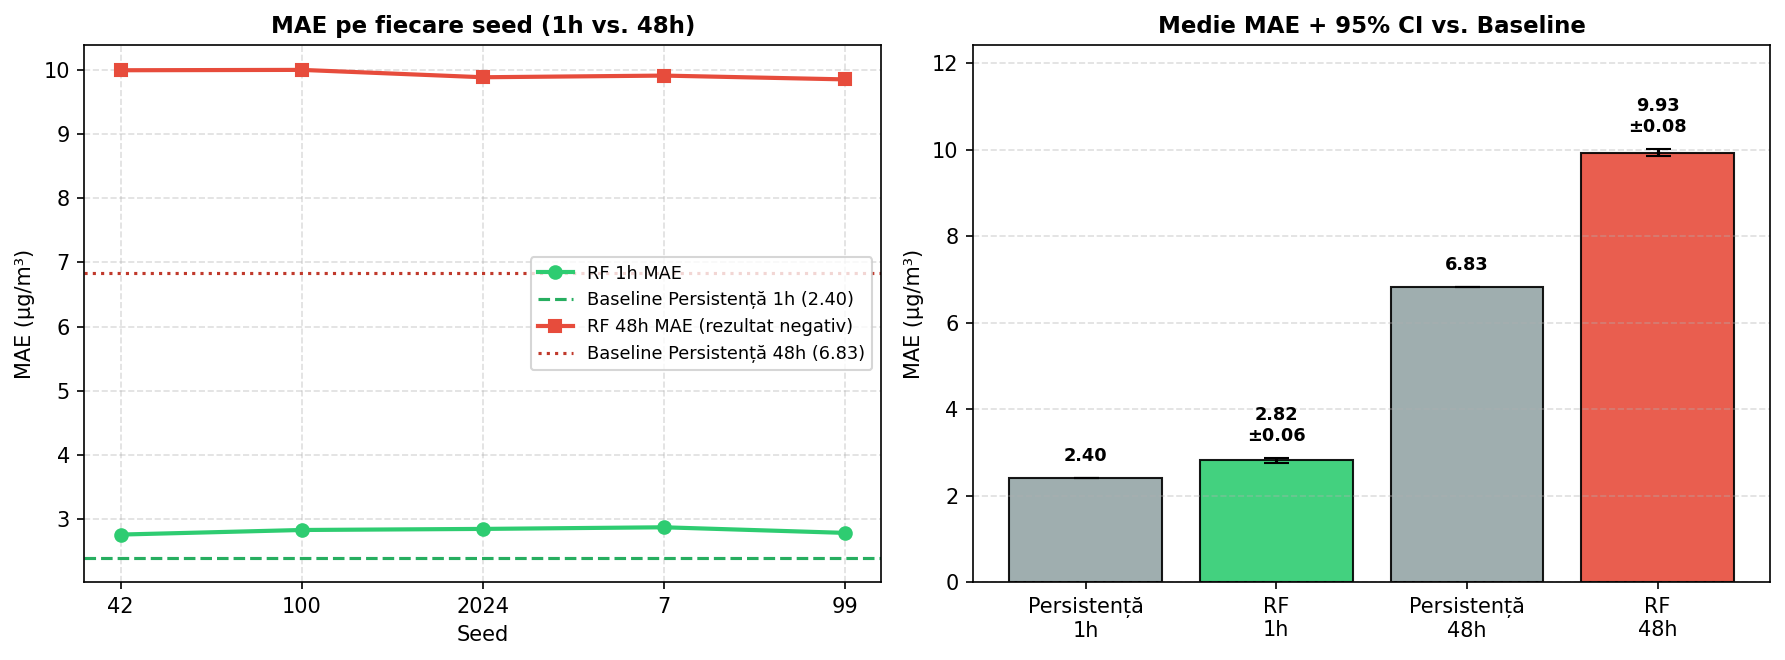

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df_exp = df_final.copy().sort_values("datetime").reset_index(drop=True)
df_exp["pm25_lag1"] = df_exp["pm25"].shift(1)
df_exp["pm25_lag24"] = df_exp["pm25"].shift(24)
df_exp = df_exp.dropna().reset_index(drop=True)

features = ["pm25_lag1", "pm25_lag24", "t2m_celsius", "wind_speed", "blh"]
horizon = 48

X_all, Y_all = [], []
for i in range(len(df_exp) - horizon):
    X_all.append(df_exp.loc[i, features].values)
    Y_all.append(df_exp.loc[i + 1 : i + horizon, "pm25"].values)

X_all = np.array(X_all)
Y_all = np.array(Y_all)

split_idx = int(len(X_all) * 0.8)
X_train, X_test = X_all[:split_idx], X_all[split_idx:]
Y_train, Y_test = Y_all[:split_idx], Y_all[split_idx:]

y_true_1h = Y_test[:, 0]
y_pers_1h = X_test[:, 0]

pm25_at_t_test = np.array([df_exp.loc[split_idx + k, "pm25"] for k in range(len(X_test))])
y_pers_48h = np.repeat(pm25_at_t_test[:, None], horizon, axis=1)

base_mae_1h = mean_absolute_error(y_true_1h, y_pers_1h)
base_rmse_1h = np.sqrt(mean_squared_error(y_true_1h, y_pers_1h))
base_mae_48h = mean_absolute_error(Y_test.ravel(), y_pers_48h.ravel())
base_rmse_48h = np.sqrt(mean_squared_error(Y_test.ravel(), y_pers_48h.ravel()))

print(f"Baseline Persistență 1h  -> MAE: {base_mae_1h:.2f} | RMSE: {base_rmse_1h:.2f}")
print(f"Baseline Persistență 48h -> MAE: {base_mae_48h:.2f} | RMSE: {base_rmse_48h:.2f}")
print("-" * 75)

seeds = [42, 100, 2024, 7, 99]
mae1_list, rmse1_list = [], []
mae48_list, rmse48_list = [], []

for s in seeds:
    m1 = RandomForestRegressor(n_estimators=100, random_state=s, n_jobs=-1).fit(X_train, Y_train[:, 0])
    p1 = m1.predict(X_test)
    mae1 = mean_absolute_error(y_true_1h, p1)
    rmse1 = np.sqrt(mean_squared_error(y_true_1h, p1))

    m48 = RandomForestRegressor(n_estimators=100, random_state=s, n_jobs=-1).fit(X_train, Y_train)
    p48 = m48.predict(X_test)
    mae48 = mean_absolute_error(Y_test.ravel(), p48.ravel())
    rmse48 = np.sqrt(mean_squared_error(Y_test.ravel(), p48.ravel()))

    mae1_list.append(mae1)
    rmse1_list.append(rmse1)
    mae48_list.append(mae48)
    rmse48_list.append(rmse48)

    print(f"Seed {s:<4} | 1h MAE: {mae1:.2f}, RMSE: {rmse1:.2f} | 48h MAE: {mae48:.2f}, RMSE: {rmse48:.2f}")

def ci95_margin(vals):
    vals = np.asarray(vals, dtype=float)
    m = np.mean(vals)
    _, hi = stats.t.interval(0.95, len(vals) - 1, loc=m, scale=stats.sem(vals))
    return m, hi - m

m1_mean, m1_ci = ci95_margin(mae1_list)
m48_mean, m48_ci = ci95_margin(mae48_list)

# --- GRAFIC PENTRU SLIDE 2 ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

# 1. Valori MAE per seed (1h vs 48h)
x = np.arange(len(seeds))
ax1.plot(x, mae1_list, marker="o", linewidth=2, color="#2ecc71", label="RF 1h MAE")
ax1.axhline(base_mae_1h, linestyle="--", color="#27ae60", label=f"Baseline Persistență 1h ({base_mae_1h:.2f})")

ax1.plot(x, mae48_list, marker="s", linewidth=2, color="#e74c3c", label="RF 48h MAE (rezultat negativ)")
ax1.axhline(base_mae_48h, linestyle=":", color="#c0392b", label=f"Baseline Persistență 48h ({base_mae_48h:.2f})")

ax1.set_title("MAE pe fiecare seed (1h vs. 48h)", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels([str(s) for s in seeds])
ax1.set_xlabel("Seed")
ax1.set_ylabel("MAE (µg/m³)")
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(fontsize=8.5)

# 2. Medie + 95% CI comparativ cu Baseline
labels = ["Persistență\n1h", "RF\n1h", "Persistență\n48h", "RF\n48h"]
means = [base_mae_1h, m1_mean, base_mae_48h, m48_mean]
errs = [0, m1_ci, 0, m48_ci]
bar_colors = ["#95a5a6", "#2ecc71", "#95a5a6", "#e74c3c"]

bars = ax2.bar(labels, means, yerr=errs, capsize=6, color=bar_colors, edgecolor="black", alpha=0.9)
ax2.set_title("Medie MAE + 95% CI vs. Baseline", fontsize=11, fontweight="bold")
ax2.set_ylabel("MAE (µg/m³)")
ax2.set_ylim(0, max(means) * 1.25)
ax2.grid(axis="y", linestyle="--", alpha=0.4)

for bar, val, err in zip(bars, means, errs):
    txt = f"{val:.2f}" if err == 0 else f"{val:.2f}\n±{err:.2f}"
    ax2.text(bar.get_x() + bar.get_width() / 2, val + err + 0.3, txt,
             ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig("slide2_seeduri_grafic.png", dpi=300, bbox_inches="tight")
plt.show()

,Orizont,Persistență MAE (µg/m³),RF MAE ± 95% CI (µg/m³),Status
0,t+1h,1.52,2.94 ± 0.09,NEGATIV (sub baseline)
1,t+6h,4.27,4.66 ± 0.19,NEGATIV (sub baseline)
2,t+12h,5.49,8.25 ± 0.31,NEGATIV (sub baseline)
3,t+24h,7.71,11.94 ± 0.19,NEGATIV (sub baseline)
4,t+36h,8.10,13.50 ± 0.24,NEGATIV (sub baseline)
5,t+48h,7.23,9.37 ± 0.19,NEGATIV (sub baseline)


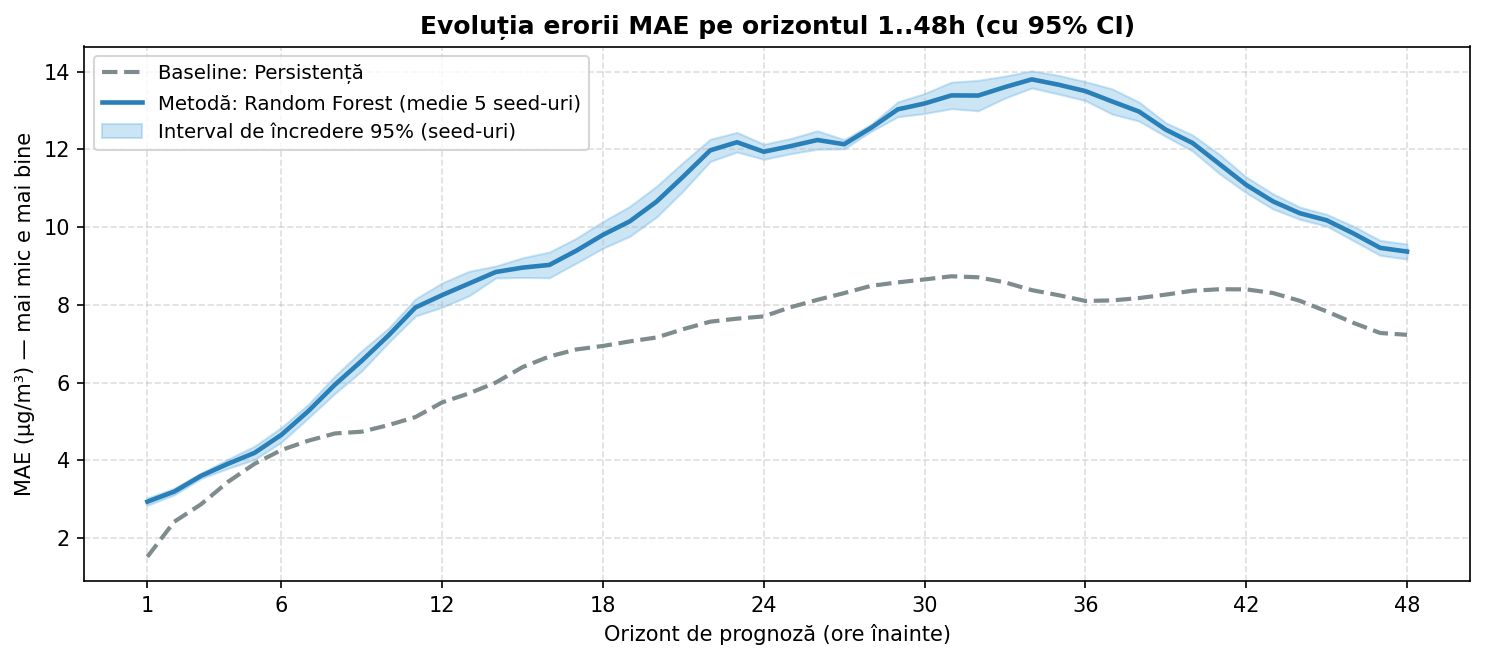

In [44]:
#Prognoza per ora

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Pregătire date (exact ca în celulele anterioare)
df_exp = df_final.copy().sort_values("datetime").reset_index(drop=True)
df_exp["pm25_lag1"] = df_exp["pm25"].shift(1)
df_exp["pm25_lag24"] = df_exp["pm25"].shift(24)
df_exp = df_exp.dropna().reset_index(drop=True)

features = ["pm25_lag1", "pm25_lag24", "t2m_celsius", "wind_speed", "blh"]
horizon = 48

X_all, Y_all = [], []
for i in range(len(df_exp) - horizon):
    X_all.append(df_exp.loc[i, features].values)
    Y_all.append(df_exp.loc[i + 1 : i + horizon, "pm25"].values)

X_all = np.array(X_all)
Y_all = np.array(Y_all)

split_idx = int(len(X_all) * 0.8)
X_train, X_test = X_all[:split_idx], X_all[split_idx:]
Y_train, Y_test = Y_all[:split_idx], Y_all[split_idx:]

# Baseline Persistență pe fiecare oră h = 1..48
pm25_at_t_test = np.array([df_exp.loc[split_idx + k, "pm25"] for k in range(len(X_test))])
mae_pers_per_hour = [
    mean_absolute_error(Y_test[:, h], pm25_at_t_test) for h in range(horizon)
]

# 2. Rulări Random Forest pe 5 seed-uri și MAE per oră (1..48h)
seeds = [42, 100, 2024, 7, 99]
mae_rf_seeds_hours = []  # shape: (5, 48)

for s in seeds:
    m48 = RandomForestRegressor(n_estimators=100, random_state=s, n_jobs=-1).fit(X_train, Y_train)
    p48 = m48.predict(X_test)
    mae_h = [mean_absolute_error(Y_test[:, h], p48[:, h]) for h in range(horizon)]
    mae_rf_seeds_hours.append(mae_h)

mae_rf_seeds_hours = np.array(mae_rf_seeds_hours)
mean_mae_h = np.mean(mae_rf_seeds_hours, axis=0)
_, hi_h = stats.t.interval(
    0.95, len(seeds) - 1, loc=mean_mae_h, scale=stats.sem(mae_rf_seeds_hours, axis=0)
)
ci_mae_h = hi_h - mean_mae_h

# 3. Tabel rezumat pe orele cheie (1h, 6h, 12h, 24h, 36h, 48h)
ore_cheie = [1, 6, 12, 24, 36, 48]
rows_ore = []
for h in ore_cheie:
    idx = h - 1
    pers_val = mae_pers_per_hour[idx]
    rf_val = mean_mae_h[idx]
    rf_ci = ci_mae_h[idx]
    status = "Pozitiv (bate baseline)" if rf_val < pers_val else "NEGATIV (sub baseline)"
    rows_ore.append({
        "Orizont": f"t+{h}h",
        "Persistență MAE (µg/m³)": round(pers_val, 2),
        "RF MAE ± 95% CI (µg/m³)": f"{rf_val:.2f} ± {rf_ci:.2f}",
        "Status": status
    })

df_ore_cheie = pd.DataFrame(rows_ore)
display(df_ore_cheie)

# 4. Grafic 1..48h cu bandă de încredere 95% (cerut la CP3)
hours = np.arange(1, horizon + 1)
plt.figure(figsize=(10, 4.5), dpi=150)

plt.plot(hours, mae_pers_per_hour, "--", color="#7f8c8d", linewidth=2, label="Baseline: Persistență")
plt.plot(hours, mean_mae_h, "-", color="#2980b9", linewidth=2.2, label="Metodă: Random Forest (medie 5 seed-uri)")
plt.fill_between(
    hours,
    mean_mae_h - ci_mae_h,
    mean_mae_h + ci_mae_h,
    color="#3498db",
    alpha=0.25,
    label="Interval de încredere 95% (seed-uri)"
)

plt.title("Evoluția erorii MAE pe orizontul 1..48h (cu 95% CI)", fontsize=12, fontweight="bold")
plt.xlabel("Orizont de prognoză (ore înainte)", fontsize=10)
plt.ylabel("MAE (µg/m³) — mai mic e mai bine", fontsize=10)
plt.xticks([1, 6, 12, 18, 24, 30, 36, 42, 48])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.savefig("cp3_eroare_pe_ore_48h.png", dpi=300, bbox_inches="tight")
plt.show()